# Proyecto final de Machine Learning
## Predicción del tiempo de retención cromatográfica mediante descriptores moleculares

## Introducción

En cromatografía, el tiempo de retención ayuda a caracterizar la separación de los compuestos. Estimarlo a partir de su estructura molecular puede apoyar el análisis de muestras y orientar el desarrollo de métodos, reduciendo la dependencia de mediciones experimentales para cada compuesto. Este proyecto desarrolla un flujo QSRR (*Quantitative Structure–Retention Relationship*) para predecir `rt` con descriptores moleculares de RepoRT.

Se integran las mediciones de retención y los descriptores, se exploran los datos y se entrenan modelos de regresión con una metodología reproducible. El análisis incluye selección de características, pipelines, optimización de hiperparámetros, comparación estadística con Ridge y visualización exploratoria mediante t-SNE.

## Idioma

La notebook y sus explicaciones y gráficos se presentan en español. Se conservan en su forma original los nombres técnicos, las bibliotecas y los identificadores de código cuando corresponde.

## EDA

Se exploran los datos de RepoRT: se localiza el repositorio y se inspeccionan sus archivos para reconocer las fuentes de mediciones de retención y descriptores.

In [ ]:
# Descargar RepoRT solo si todavía no está disponible en el entorno
from pathlib import Path
import subprocess

repo_path = Path('RepoRT')
if not repo_path.is_dir():
    subprocess.run(['git', 'clone', 'https://github.com/michaelwitting/RepoRT.git'], check=True)
else:
    print('El repositorio RepoRT ya está disponible; se reutilizará la carpeta existente.')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Explorar la estructura para ubicar el archivo de datos principal (ej. .csv)
print("Contenido del repositorio:", os.listdir('RepoRT'))

### EDA: estructura del repositorio

Se revisan formatos y archivos disponibles para identificar los datos que se utilizarán en el análisis.

In [54]:
import glob

# Buscamos cualquier archivo dentro de RepoRT para ver qué extensiones maneja
todos_los_archivos = glob.glob('RepoRT/**/*', recursive=True)

# Filtramos para ver qué tipos de archivos hay (excluyendo carpetas)
extensiones = set(f.split('.')[-1] for f in todos_los_archivos if '.' in f)
print("Extensiones de archivos encontradas en RepoRT:", extensiones)

# Busquemos si hay archivos .RData, .rds o txt
archivos_datos = [f for f in todos_los_archivos if f.endswith(('.rdata', '.rds', '.txt', '.csv', '.tsv', '.parquet'))]
print("\nArchivos de datos principales encontrados:", archivos_datos[:15])

Extensiones de archivos encontradas en RepoRT: {'tsv', 'yaml', 'py', 'md', 'R', 'txt', 'old', 'bk', 'jar', 'html', 'Rproj', 'lock', 'pdf', 'dcf'}

Archivos de datos principales encontrados: ['RepoRT/example/0259_metadata.tsv', 'RepoRT/example/0259_rtdata.tsv', 'RepoRT/example/0259_gradient.tsv', 'RepoRT/processed_data/studies.tsv', 'RepoRT/processed_data/0075/0075_descriptors_isomeric_success.tsv', 'RepoRT/processed_data/0075/0075_metadata.tsv', 'RepoRT/processed_data/0075/0075_fingerprints_ecfp6_isomeric_success.tsv', 'RepoRT/processed_data/0075/0075_rtdata_isomeric_failed.tsv', 'RepoRT/processed_data/0075/0075_gradient.tsv', 'RepoRT/processed_data/0075/0075_rtdata_canonical_success.tsv', 'RepoRT/processed_data/0075/0075_info.tsv', 'RepoRT/processed_data/0075/0075_fingerprints_pubchem_canonical_success.tsv', 'RepoRT/processed_data/0075/0075_rtdata_isomeric_success.tsv', 'RepoRT/processed_data/0075/0075_fingerprints_maccs_canonical_success.tsv', 'RepoRT/processed_data/0075/0075_fingerp

### EDA: tiempos de retención

Se recopilan archivos de distintos estudios y se consolidan sus mediciones de retención, conservando el identificador de estudio.

In [55]:
import glob
import pandas as pd

# 1. Buscamos todos los archivos de datos de retención (rtdata) en formato tsv dentro de processed_data
archivos_rt = sorted(glob.glob('RepoRT/processed_data/**/*rtdata*.tsv', recursive=True))

print(f"¡Se encontraron {len(archivos_rt)} estudios con datos de retención en el repositorio!")

# Se procesarán los primeros 80 estudios disponibles para ampliar la muestra.
MAX_STUDIES = 80
lista_dfs = []

for archivo in archivos_rt[:MAX_STUDIES]:
    try:
        df_temp = pd.read_csv(archivo, sep='\t', low_memory=False)
        # Opcional: Agregar una columna para identificar el estudio de origen basado en la ruta
        estudio_id = archivo.split('/')[-2]
        df_temp['study_id'] = estudio_id
        lista_dfs.append(df_temp)
    except Exception as e:
        print(f"Error al leer {archivo}: {e}")

# 3. Fusionamos todo en un gran DataFrame global
if len(lista_dfs) > 0:
    df_global_tsv = pd.concat(lista_dfs, ignore_index=True)
    print("\n¡Dataset global consolidado con éxito desde archivos TSV!")
    print(f"Dimensiones del dataset masivo: {df_global_tsv.shape[0]} filas y {df_global_tsv.shape[1]} columnas.")
    display(df_global_tsv.head(3))
else:
    print("No se pudieron cargar los archivos TSV.")

¡Se encontraron 1242 estudios con datos de retención en el repositorio!

¡Dataset global consolidado con éxito desde archivos TSV!
Dimensiones del dataset masivo: 6490 filas y 16 columnas.


,id,name,formula,rt,smiles.std,inchi.std,inchikey.std,classyfire.kingdom,classyfire.superclass,classyfire.class,classyfire.subclass,classyfire.level5,classyfire.level6,comment,study_id,status
0,0001_00001,epicatechin,C15H14O6,12.070,C1C(C(OC2=CC(=CC(=C21)O)O)C3=CC(=C(C=C3)O)O)O,InChI=1S/C15H14O6/c16-8-4-11(18)9-6-13(20)15(2...,PFTAWBLQPZVEMU-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Phenylpropanoids and polyketides (CHEMONTID:00...,Flavonoids (CHEMONTID:0000334),Flavans (CHEMONTID:0000337),Flavan-3-ols (CHEMONTID:0003012),Catechins (CHEMONTID:0001584),NaN,0001,NaN
1,0001_00002,epicatechin gallate,C22H18O10,15.990,C1C(C(OC2=CC(=CC(=C21)O)O)C3=CC(=C(C=C3)O)O)OC...,InChI=1S/C22H18O10/c23-11-6-14(25)12-8-19(32-2...,LSHVYAFMTMFKBA-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Phenylpropanoids and polyketides (CHEMONTID:00...,Flavonoids (CHEMONTID:0000334),Flavans (CHEMONTID:0000337),Flavan-3-ols (CHEMONTID:0003012),Catechins (CHEMONTID:0001584),NaN,0001,NaN
2,0001_00003,gallocatechin,C15H14O7,8.675,C1C(C(OC2=CC(=CC(=C21)O)O)C3=CC(=C(C(=C3)O)O)O)O,InChI=1S/C15H14O7/c16-7-3-9(17)8-5-12(20)15(22...,XMOCLSLCDHWDHP-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Phenylpropanoids and polyketides (CHEMONTID:00...,Flavonoids (CHEMONTID:0000334),Flavans (CHEMONTID:0000337),Flavan-3-ols (CHEMONTID:0003012),Catechins (CHEMONTID:0001584),NaN,0001,NaN


### EDA: descriptores moleculares

Se localizan e inspeccionan archivos de descriptores para conocer su estructura antes de integrarlos con las mediciones.

In [56]:
# Buscamos los archivos de descriptores (descriptors) correspondientes a los estudios
archivos_desc = glob.glob('RepoRT/processed_data/**/*descriptors*.tsv', recursive=True)
print(f"Se encontraron {len(archivos_desc)} archivos de descriptores moleculares.")

# Cargamos un archivo de descriptores de ejemplo para ver su estructura y combinarlo
if len(archivos_desc) > 0:
    df_desc_ejemplo = pd.read_csv(archivos_desc[0], sep='\t', low_memory=False)
    print("\nEstructura de los descriptores moleculares:")
    print(f"Dimensiones: {df_desc_ejemplo.shape}")
    display(df_desc_ejemplo.head(3))

Se encontraron 838 archivos de descriptores moleculares.

Estructura de los descriptores moleculares:
Dimensiones: (36, 287)


,id,Wlambda1.unity,Wlambda2.unity,Wlambda3.unity,Wnu1.unity,Wnu2.unity,Wgamma1.unity,Wgamma2.unity,Wgamma3.unity,Weta1.unity,...,LOBMIN,GRAV.1,GRAV.2,GRAV.3,GRAVH.1,GRAVH.2,GRAVH.3,GRAV.4,GRAV.5,GRAV.6
0,0075_00002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0075_00003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0075_00006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Feature Extraction

RepoRT proporciona descriptores moleculares precomputados, que se integran con las mediciones de retención por estudio e identificador del compuesto para formar la tabla QSRR. La rúbrica reserva la extracción de características para datos no estructurados que usan transfer learning; como este proyecto usa datos tabulares y no aplica transfer learning, no corresponde extraer características desde datos crudos.

In [57]:
import glob
import pandas as pd

# 1. Buscamos todos los archivos de retención y de descriptores
archivos_rt = sorted(glob.glob('RepoRT/processed_data/**/*rtdata*.tsv', recursive=True))
archivos_desc = glob.glob('RepoRT/processed_data/**/*descriptors*.tsv', recursive=True)

# Creamos diccionarios para indexarlos rápido por el código del estudio (ej. '0402')
dict_desc = {}
for desc_path in archivos_desc:
    # Extraemos el study_id de la ruta o del nombre del archivo
    study_id = desc_path.split('/')[-2]
    dict_desc[study_id] = desc_path

lista_estudios_fusionados = []

# 2. Iteramos sobre los estudios de retención y buscamos su par de descriptores
for rt_path in archivos_rt[:MAX_STUDIES]:
    study_id = rt_path.split('/')[-2]

    if study_id in dict_desc:
        try:
            # Leemos ambos archivos TSV
            df_rt = pd.read_csv(rt_path, sep='\t', low_memory=False)
            df_desc = pd.read_csv(dict_desc[study_id], sep='\t', low_memory=False)

            # Unimos ambas tablas usando la columna 'id' que comparten
            if 'id' in df_rt.columns and 'id' in df_desc.columns:
                df_merged = pd.merge(df_rt, df_desc, on='id', how='inner')
                df_merged['study_id'] = study_id
                lista_estudios_fusionados.append(df_merged)
        except Exception as e:
            print(f"Error procesando el estudio {study_id}: {e}")

# 3. Consolidamos el gran dataset global cruzado
if len(lista_estudios_fusionados) > 0:
    df_global_qsr = pd.concat(lista_estudios_fusionados, ignore_index=True)
    print("\n¡Fusión completada con éxito!")
    print(f"Dataset masivo QSRR consolidado: {df_global_qsr.shape[0]} filas (moléculas) y {df_global_qsr.shape[1]} columnas (descriptores + retención).")
    display(df_global_qsr.head(3))
else:
    print("No se pudieron fusionar los estudios.")


¡Fusión completada con éxito!
Dataset masivo QSRR consolidado: 2968 filas (moléculas) y 302 columnas (descriptores + retención).


,id,name,formula,rt,smiles.std,inchi.std,inchikey.std,classyfire.kingdom,classyfire.superclass,classyfire.class,...,GRAV.2,GRAV.3,GRAVH.1,GRAVH.2,GRAVH.3,GRAV.4,GRAV.5,GRAV.6,study_id,status
0,0001_00001,epicatechin,C15H14O6,12.070,C1C(C(OC2=CC(=CC(=C21)O)O)C3=CC(=C(C=C3)O)O)O,InChI=1S/C15H14O6/c16-8-4-11(18)9-6-13(20)15(2...,PFTAWBLQPZVEMU-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Phenylpropanoids and polyketides (CHEMONTID:00...,Flavonoids (CHEMONTID:0000334),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001,NaN
1,0001_00002,epicatechin gallate,C22H18O10,15.990,C1C(C(OC2=CC(=CC(=C21)O)O)C3=CC(=C(C=C3)O)O)OC...,InChI=1S/C22H18O10/c23-11-6-14(25)12-8-19(32-2...,LSHVYAFMTMFKBA-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Phenylpropanoids and polyketides (CHEMONTID:00...,Flavonoids (CHEMONTID:0000334),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001,NaN
2,0001_00003,gallocatechin,C15H14O7,8.675,C1C(C(OC2=CC(=CC(=C21)O)O)C3=CC(=C(C(=C3)O)O)O)O,InChI=1S/C15H14O7/c16-7-3-9(17)8-5-12(20)15(22...,XMOCLSLCDHWDHP-UHFFFAOYSA-N,Organic compounds (CHEMONTID:0000000),Phenylpropanoids and polyketides (CHEMONTID:00...,Flavonoids (CHEMONTID:0000334),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001,NaN


## EDA del conjunto integrado

Se resumen las dimensiones, los tipos de variables, los valores faltantes y la distribución del tiempo de retención `rt`. Los gráficos permiten inspeccionar la variable objetivo y las columnas con más datos ausentes.

Dimensiones del conjunto QSRR: 2968 filas x 302 columnas
Tipos de datos:
float64    172
int64      115
object      15
Name: count, dtype: int64

Estadísticas descriptivas de rt:
count    2968.000000
mean        7.788195
std         7.130195
min         0.120000
25%         1.440000
50%         6.500000
75%        12.397714
max        49.600000
Name: rt, dtype: float64

Porcentaje de valores faltantes en los 15 descriptores con más nulos:
WK.unity    100.0
MOMI.XY     100.0
MOMI.XZ     100.0
MOMI.YZ     100.0
MOMI.R      100.0
LOBMAX      100.0
LOBMIN      100.0
GRAV.1      100.0
WD.unity    100.0
GRAV.3      100.0
GRAVH.1     100.0
GRAVH.2     100.0
GRAVH.3     100.0
GRAV.4      100.0
GRAV.5      100.0
dtype: float64


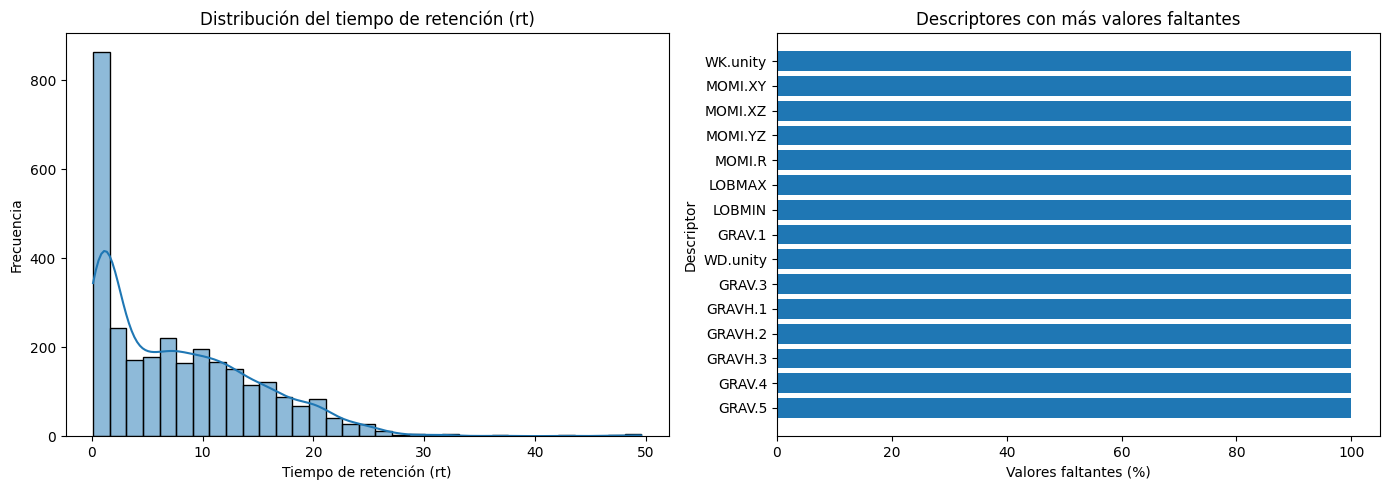

In [58]:

# Resumen estructural y calidad de los datos integrados
print(f"Dimensiones del conjunto QSRR: {df_global_qsr.shape[0]} filas x {df_global_qsr.shape[1]} columnas")
print("Tipos de datos:")
print(df_global_qsr.dtypes.value_counts())

columna_rt_eda = 'rt'
if columna_rt_eda not in df_global_qsr.columns:
    raise KeyError(f"No se encontró la variable objetivo esperada: {columna_rt_eda}")

print()
print("Estadísticas descriptivas de rt:")
print(df_global_qsr[columna_rt_eda].describe())

columnas_numericas_eda = df_global_qsr.select_dtypes(include=np.number).columns
columnas_descriptores_eda = columnas_numericas_eda.drop(columna_rt_eda, errors='ignore')
porcentaje_nulos = (
    df_global_qsr[columnas_descriptores_eda]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .head(15)
)
print()
print("Porcentaje de valores faltantes en los 15 descriptores con más nulos:")
print(porcentaje_nulos)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_global_qsr[columna_rt_eda].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Distribución del tiempo de retención (rt)')
axes[0].set_xlabel('Tiempo de retención (rt)')
axes[0].set_ylabel('Frecuencia')

axes[1].barh(porcentaje_nulos.index.astype(str), porcentaje_nulos.values)
axes[1].invert_yaxis()
axes[1].set_title('Descriptores con más valores faltantes')
axes[1].set_xlabel('Valores faltantes (%)')
axes[1].set_ylabel('Descriptor')
plt.tight_layout()
plt.show()

## Feature Selection

Se seleccionan como predictores las columnas numéricas, se excluye el objetivo y se eliminan filas sin valor de retención. `VarianceThreshold(0.01)` descarta características de baja varianza.

## Pipelines

El flujo de selección, imputación por mediana y Random Forest se encapsula en un pipeline de scikit-learn para aplicar el preprocesamiento dentro de cada ajuste y evitar fuga de información entre particiones.

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Identificamos la columna objetivo (tiempo de retención, que suele llamarse 'rt' o similar)
# Busquemos columnas que contengan 'rt' o el valor numérico de retención
columna_rt = [c for c in df_global_qsr.columns if 'rt' in c.lower()][0] # O ajusta el nombre exacto si lo conoces
print(f"Columna objetivo detectada para el tiempo de retención: {columna_rt}")

# 2. Seleccionamos las características (excluyendo metadatos, id, fórmulas, smiles, etc.)
# Tomamos únicamente las columnas numéricas que actúan como descriptores
X = df_global_qsr.select_dtypes(include=['float64', 'int64']).drop(columns=[columna_rt], errors='ignore')
y = df_global_qsr[columna_rt]

# Eliminamos filas donde la variable objetivo sea nula (NaN)
filas_validas = y.notna()
X = X[filas_validas]
y = y[filas_validas]

print(f"Dimensiones finales para entrenamiento - X: {X.shape}, y: {y.shape}")

# 3. Construimos el Pipeline masivo con VarianceThreshold + Imputador + Random Forest
pipeline_masivo = Pipeline([
    ('var_thresh', VarianceThreshold(threshold=0.01)), # Elimina descriptores constantes
    ('imputer', SimpleImputer(strategy='median')),     # Rellena nulos
    ('model', RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1))
])

# 4. División de datos y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nEntrenando modelo con el dataset masivo de RepoRT...")
pipeline_masivo.fit(X_train, y_train)

# 5. Evaluación
y_pred = pipeline_masivo.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"¡Modelo entrenado con éxito a gran escala!")
print(f"R² Score en conjunto de prueba: {r2:.4f}")

Columna objetivo detectada para el tiempo de retención: rt
Dimensiones finales para entrenamiento - X: (2968, 286), y: (2968,)

Entrenando modelo con el dataset masivo de RepoRT...


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_variance_threshold.py:114: RuntimeWarning: Degrees of freedom <= 0 for slice.
  self.variances_ = np.nanvar(X, axis=0)


¡Modelo entrenado con éxito a gran escala!
R² Score en conjunto de prueba: 0.5092


## Validación del modelo base

Se evalúa el pipeline de Random Forest con una partición de entrenamiento y prueba. Las validaciones posteriores se realizan solo con entrenamiento, manteniendo la prueba reservada para la evaluación final.

In [60]:
from sklearn.model_selection import RepeatedKFold, cross_val_score
import numpy as np

# Validación repeated k-fold: 5 pliegues y 2 repeticiones (opción de menor costo de la rúbrica)
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

# Evaluamos el pipeline completo con validación cruzada
scores = cross_val_score(pipeline_masivo, X_train, y_train, scoring='r2', cv=cv, n_jobs=-1)

print(f"R² scores en validación cruzada: {scores}")
print(f"R² promedio: {scores.mean():.4f} (+/- {scores.std():.4f})")

R² scores en validación cruzada: [0.44712397 0.57515464 0.40382976 0.46529792 0.44076591 0.39084118
 0.41590734 0.44799556 0.44199945 0.4372474 ]
R² promedio: 0.4466 (+/- 0.0479)


## Optimización de hiperparámetros

Se buscan configuraciones de Random Forest mediante validación cruzada en el conjunto de entrenamiento, incluyendo árboles sin límite explícito de profundidad y alternativas finitas. Luego, el mejor estimador se evalúa una sola vez en el conjunto de prueba con R², MSE y RMSE.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_variance_threshold.py:114: RuntimeWarning: Degrees of freedom <= 0 for slice.
  self.variances_ = np.nanvar(X, axis=0)


Mejores hiperparámetros encontrados: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__max_depth': 10}
Mejor R² medio en validación cruzada: 0.4545
R2 del mejor modelo en prueba: 0.4996
MSE del mejor modelo en prueba: 27.3896
RMSE del mejor modelo en prueba: 5.2335


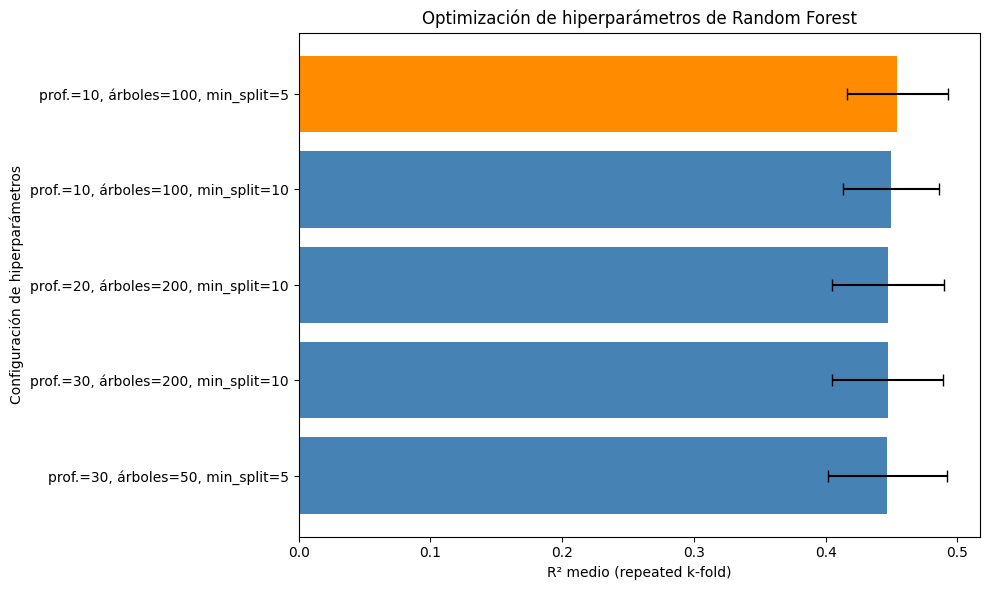

In [61]:
from sklearn.model_selection import RandomizedSearchCV

# Definimos los hiperparámetros a explorar
param_dist = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10]
}

# Buscamos la mejor combinación usando validación cruzada
search = RandomizedSearchCV(
    estimator=pipeline_masivo,
    param_distributions=param_dist,
    n_iter=5,
    cv=cv,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print(f"Mejores hiperparámetros encontrados: {search.best_params_}")
print(f"Mejor R² medio en validación cruzada: {search.best_score_:.4f}")

# Evaluamos una sola vez el mejor modelo en el conjunto de prueba reservado
y_test_pred = search.best_estimator_.predict(X_test)
r2_test_optimizado = r2_score(y_test, y_test_pred)
mse_test_optimizado = mean_squared_error(y_test, y_test_pred)
rmse_test_optimizado = np.sqrt(mse_test_optimizado)

print(f"R2 del mejor modelo en prueba: {r2_test_optimizado:.4f}")
print(f"MSE del mejor modelo en prueba: {mse_test_optimizado:.4f}")
print(f"RMSE del mejor modelo en prueba: {rmse_test_optimizado:.4f}")

# Gráfica de las configuraciones probadas y su R² medio en repeated k-fold
resultados_busqueda = pd.DataFrame(search.cv_results_)
resultados_busqueda['configuracion'] = [
    f"prof.={prof}, árboles={arboles}, min_split={min_split}"
    for prof, arboles, min_split in zip(
        resultados_busqueda['param_model__max_depth'],
        resultados_busqueda['param_model__n_estimators'],
        resultados_busqueda['param_model__min_samples_split']
    )
]
orden = np.argsort(resultados_busqueda['mean_test_score'].to_numpy())
colores = [
    'darkorange' if indice == search.best_index_ else 'steelblue'
    for indice in orden
]
plt.figure(figsize=(10, 6))
plt.barh(
    resultados_busqueda['configuracion'].iloc[orden],
    resultados_busqueda['mean_test_score'].iloc[orden],
    xerr=resultados_busqueda['std_test_score'].iloc[orden],
    color=colores,
    capsize=4
)
plt.xlabel('R² medio (repeated k-fold)')
plt.ylabel('Configuración de hiperparámetros')
plt.title('Optimización de hiperparámetros de Random Forest')
plt.tight_layout()
plt.show()

## Curva de aprendizaje: R²

Se compara el R² de entrenamiento y validación a medida que aumenta el tamaño de la muestra de entrenamiento, para explorar la evolución del ajuste.

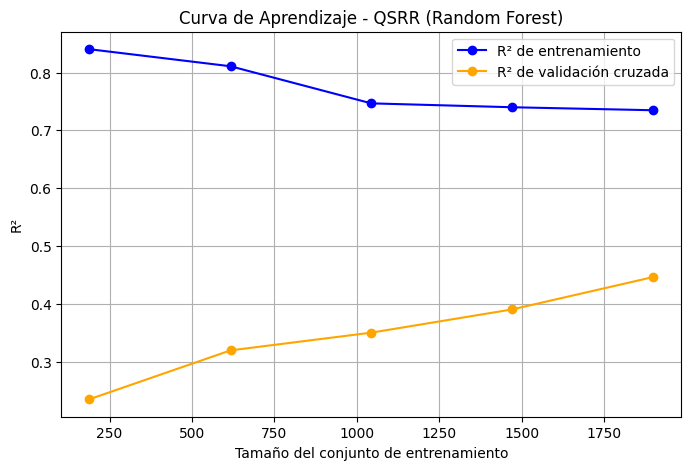

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedKFold, learning_curve

# Usamos la validación cruzada repetida que ya definiste o creamos una para la curva
cv_reg = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=pipeline_masivo, # Tu pipeline real
    X=X_train,
    y=y_train,
    cv=cv_reg,
    scoring='r2',  # Métrica de regresión
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5)
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Graficar curva de aprendizaje
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='R² de entrenamiento', marker='o', color='blue')
plt.plot(train_sizes, val_mean, label='R² de validación cruzada', marker='o', color='orange')
plt.xlabel('Tamaño del conjunto de entrenamiento')
plt.ylabel('R²')
plt.title('Curva de Aprendizaje - QSRR (Random Forest)')
plt.legend(loc='best')
plt.grid(True)
plt.show()

## Curva de aprendizaje: error cuadrático medio

Se compara el MSE de entrenamiento y validación con distintos tamaños de muestra; valores menores indican errores de predicción más bajos.

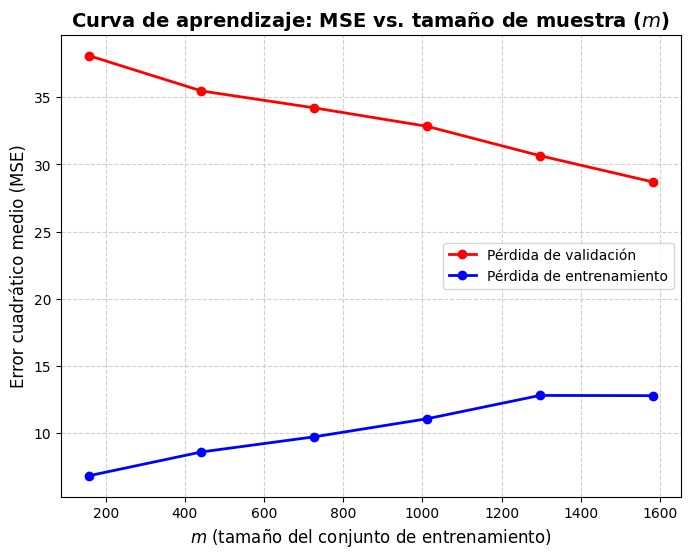

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Generamos tamaños fraccionarios para el conjunto de entrenamiento (m)
train_sizes_fraction = np.linspace(0.1, 1.0, 6)

train_sizes_abs, train_scores, val_scores = learning_curve(
    estimator=pipeline_masivo,
    X=X_train,
    y=y_train,
    cv=3,
    scoring='neg_mean_squared_error', # Usamos MSE como medida de pérdida
    n_jobs=-1,
    train_sizes=train_sizes_fraction
)

# Convertimos las puntuaciones negativas en MSE positivo
train_loss_mean = -np.mean(train_scores, axis=1)
val_loss_mean = -np.mean(val_scores, axis=1)

# Gráfico de la pérdida frente al tamaño de muestra (m)
plt.figure(figsize=(8, 6))
plt.plot(train_sizes_abs, val_loss_mean, label='Pérdida de validación', color='red', marker='o', linewidth=2)
plt.plot(train_sizes_abs, train_loss_mean, label='Pérdida de entrenamiento', color='blue', marker='o', linewidth=2)

plt.xlabel('$m$ (tamaño del conjunto de entrenamiento)', fontsize=12)
plt.ylabel('Error cuadrático medio (MSE)', fontsize=12)
plt.title('Curva de aprendizaje: MSE vs. tamaño de muestra ($m$)', fontsize=14, fontweight='bold')
plt.legend(loc='center right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Curva de validación de Ridge: regularización λ

Ridge regulariza sus coeficientes con `alpha` (λ). Se compara el MSE de entrenamiento y validación para varios valores en escala logarítmica. Valores pequeños penalizan poco y pueden favorecer sobreajuste; valores grandes penalizan más y pueden producir subajuste. Se escoge el λ con menor MSE medio de validación cruzada, usando solo el conjunto de entrenamiento. Los descriptores se estandarizan dentro del pipeline.

Mejor lambda de Ridge: 0.3162
MSE medio de validación en el mejor lambda: 32.4256


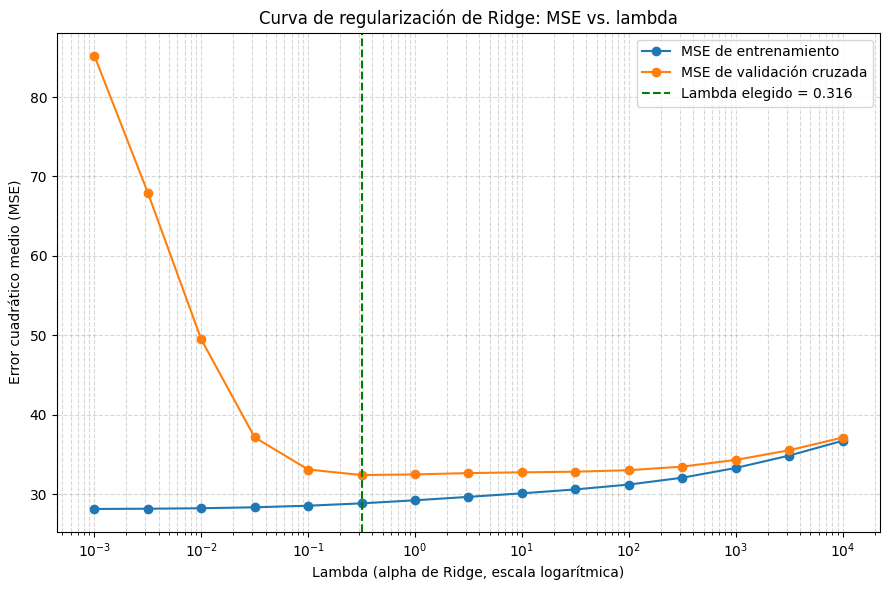

In [64]:
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import validation_curve

lambdas = np.logspace(-3, 4, 15)
pipeline_ridge = Pipeline([
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('var_thresh', VarianceThreshold(threshold=0.01)),
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

train_scores_lambda, cv_scores_lambda = validation_curve(
    estimator=pipeline_ridge,
    X=X_train,
    y=y_train,
    param_name='model__alpha',
    param_range=lambdas,
    cv=cv_reg,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

train_mse_lambda = -train_scores_lambda.mean(axis=1)
cv_mse_lambda = -cv_scores_lambda.mean(axis=1)
best_lambda_index = int(np.argmin(cv_mse_lambda))
best_lambda = float(lambdas[best_lambda_index])
print(f"Mejor lambda de Ridge: {best_lambda:.4g}")
print(f"MSE medio de validación en el mejor lambda: {cv_mse_lambda[best_lambda_index]:.4f}")
if best_lambda_index in (0, len(lambdas) - 1):
    print("Aviso: el mejor lambda está en el límite del rango; conviene ampliar la búsqueda.")

plt.figure(figsize=(9, 6))
plt.plot(lambdas, train_mse_lambda, marker='o', label='MSE de entrenamiento')
plt.plot(lambdas, cv_mse_lambda, marker='o', label='MSE de validación cruzada')
plt.axvline(best_lambda, color='green', linestyle='--', label=f'Lambda elegido = {best_lambda:.3g}')
plt.xscale('log')
plt.xlabel('Lambda (alpha de Ridge, escala logarítmica)')
plt.ylabel('Error cuadrático medio (MSE)')
plt.title('Curva de regularización de Ridge: MSE vs. lambda')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Comparación estadística de 2 técnicas ML

Se comparan Random Forest y Ridge estandarizado con las mismas particiones de repeated k-fold y una prueba pareada de Wilcoxon. Se reportan los R² medios para contextualizar la diferencia; interpreta el valor p considerando que las puntuaciones de los pliegues repetidos no son totalmente independientes.

In [65]:
from scipy.stats import wilcoxon
from sklearn.model_selection import cross_val_score
# Se reutiliza el pipeline Ridge estandarizado de la curva lambda.

# Obtenemos las puntuaciones emparejadas en repeated k-fold (5 pliegues, 2 repeticiones)
scores_rf = cross_val_score(pipeline_masivo, X_train, y_train, scoring='r2', cv=cv_reg, n_jobs=-1)
scores_ridge = cross_val_score(pipeline_ridge, X_train, y_train, scoring='r2', cv=cv_reg, n_jobs=-1)

# Aplicar test de Wilcoxon
stat, p_value = wilcoxon(scores_rf, scores_ridge)

print(f"R² medio Random Forest: {scores_rf.mean():.4f}")
print(f"R² medio Ridge: {scores_ridge.mean():.4f}")
print(f"Estadístico W: {stat:.4f}")
print(f"Valor p: {p_value:.5f}")

alpha = 0.05
if p_value < alpha:
    mejor_modelo = "Random Forest" if scores_rf.mean() > scores_ridge.mean() else "Ridge"
    print(f"Conclusión: hay una diferencia estadísticamente significativa; el mayor R² medio corresponde a {mejor_modelo}.")
else:
    print("Conclusión: no hay evidencia estadística suficiente de una diferencia entre ambos modelos.")

R² medio Random Forest: 0.4466
R² medio Ridge: 0.3474
Estadístico W: 0.0000
Valor p: 0.00195
Conclusión: hay una diferencia estadísticamente significativa; el mayor R² medio corresponde a Random Forest.


## Visualización con TSNE

Se proyecta una muestra de los descriptores a dos dimensiones y se colorea según `rt` para explorar posibles agrupamientos. La visualización es exploratoria y no evalúa por sí sola la capacidad predictiva.

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Wlambda1.unity' 'Wlambda2.unity' 'Wlambda3.unity' 'Wnu1.unity'
 'Wnu2.unity' 'Wgamma1.unity' 'Wgamma2.unity' 'Wgamma3.unity'
 'Weta1.unity' 'Weta2.unity' 'Weta3.unity' 'WT.unity' 'WA.unity'
 'WV.unity' 'WK.unity' 'WG.unity' 'WD.unity' 'VABC' 'geomShape' 'PPSA.1'
 'PPSA.2' 'PPSA.3' 'PNSA.1' 'PNSA.2' 'PNSA.3' 'DPSA.1' 'DPSA.2' 'DPSA.3'
 'FPSA.1' 'FPSA.2' 'FPSA.3' 'FNSA.1' 'FNSA.2' 'FNSA.3' 'WPSA.1' 'WPSA.2'
 'WPSA.3' 'WNSA.1' 'WNSA.2' 'WNSA.3' 'RPCG' 'RNCG' 'RPCS' 'RNCS' 'THSA'
 'TPSA' 'RHSA' 'RPSA' 'MOMI.X' 'MOMI.Y' 'MOMI.Z' 'MOMI.XY' 'MOMI.XZ'
 'MOMI.YZ' 'MOMI.R' 'LOBMAX' 'LOBMIN' 'GRAV.1' 'GRAV.2' 'GRAV.3' 'GRAVH.1'
 'GRAVH.2' 'GRAVH.3' 'GRAV.4' 'GRAV.5' 'GRAV.6']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


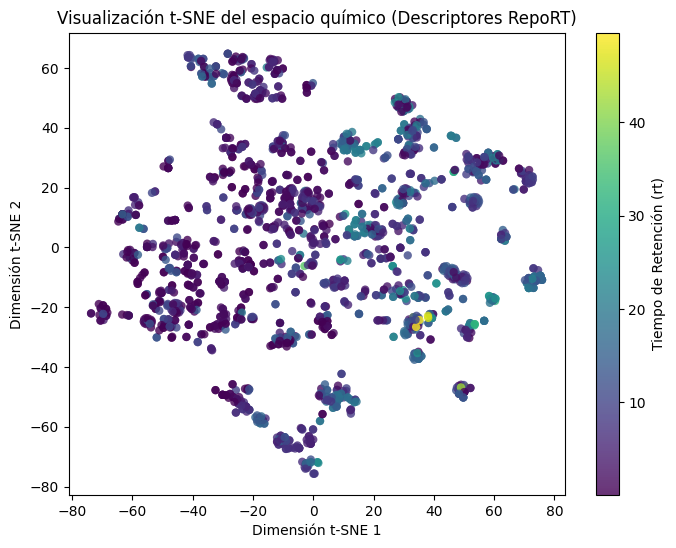

In [66]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Imputamos los valores nulos (usando la misma lógica de tu pipeline)
imputer_tsne = SimpleImputer(strategy='median')
X_imputed = imputer_tsne.fit_transform(X)

# 2. Tomamos una muestra aleatoria segura de los datos
n_samples = min(2000, X_imputed.shape[0])
rng = np.random.RandomState(42)
indices = rng.choice(X_imputed.shape[0], size=n_samples, replace=False)

X_sample = X_imputed[indices]
y_sample = y.iloc[indices]

# 3. Normalizamos los descriptores
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

# 4. Aplicamos t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

# 5. Graficar
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y_sample,
    cmap='viridis',
    alpha=0.8,
    edgecolor='none'
)
plt.colorbar(scatter, label='Tiempo de Retención (rt)')
plt.title('Visualización t-SNE del espacio químico (Descriptores RepoRT)')
plt.xlabel('Dimensión t-SNE 1')
plt.ylabel('Dimensión t-SNE 2')
plt.show()

## Interpretación de descriptores

Se visualizan las diez características con mayor importancia según el Random Forest ajustado. Estas importancias son relativas al modelo y no implican causalidad.

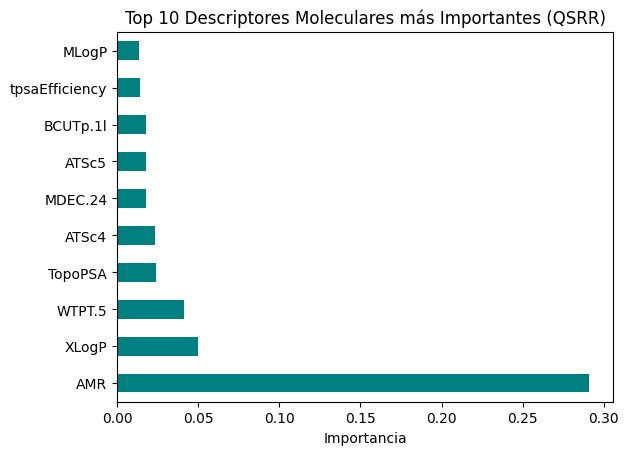

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# Extraemos el modelo entrenado y los nombres de las características post-variance threshold
modelo_rf = pipeline_masivo.named_steps['model']
selector_var = pipeline_masivo.named_steps['var_thresh']
features_validas = X.columns[selector_var.get_support()]

# Creamos un DataFrame con la importancia
importancias = pd.Series(modelo_rf.feature_importances_, index=features_validas)
importancias.nlargest(10).plot(kind='barh', color='teal')
plt.title("Top 10 Descriptores Moleculares más Importantes (QSRR)")
plt.xlabel("Importancia")
plt.show()

## Conclusiones

Se procesaron como máximo los primeros 80 estudios de retención, ordenados por ruta; después de unir los registros con sus descriptores se obtuvieron 2.968 filas QSRR y 286 predictores numéricos. El Random Forest base obtuvo R² = 0.5092 en prueba. La búsqueda seleccionó `n_estimators=100`, `max_depth=10` y `min_samples_split=5`, con R² medio de validación cruzada de 0.4545 y, en prueba, R² = 0.4996, MSE = 27.3896 y RMSE = 5.2335. Así, la búsqueda mejoró ligeramente el R² medio de validación cruzada frente al valor base (0.4466), pero no el resultado de prueba frente al modelo base; la diferencia de prueba fue pequeña.

Las curvas de aprendizaje muestran que, al crecer el conjunto de entrenamiento, el R² de validación sube aproximadamente de 0.24 a 0.45 y el MSE de validación baja de aproximadamente 38 a 29. La mejora respalda que ampliar la muestra ayuda a generalizar, pero la brecha de R² entre entrenamiento y validación aún es apreciable (aproximadamente 0.74 frente a 0.45 en el mayor tamaño mostrado); por tanto, el sobreajuste no desaparece. La curva del pipeline Ridge estandarizado seleccionó lambda = 0.3162, con MSE medio de validación cruzada = 32.4256. En la comparación repetida, Random Forest alcanzó R² medio = 0.4466 y Ridge con alpha predeterminado (1.0) R² medio = 0.3474; el test de Wilcoxon dio p = 0.00195. Esta evidencia debe interpretarse con cautela porque los pliegues de validación repetida no son independientes y Ridge en esta comparación no usa el lambda seleccionado.

La curva lambda es propia de Ridge: muestra una zona de menor error de validación alrededor del lambda seleccionado y un aumento del error al elevar demasiado la penalización, compatible con subajuste. El análisis t-SNE y la importancia de descriptores son exploratorios y no demuestran causalidad. Durante la ejecución aparecieron advertencias por descriptores completamente vacíos; conviene revisar su tratamiento antes de interpretar o desplegar el modelo. Además, la partición aleatoria de filas puede compartir estudios entre entrenamiento y prueba. Para estimar mejor la generalización a estudios nuevos, el siguiente paso recomendado es una validación agrupada por `study_id` y una comparación de modelos que evalúe Ridge con su regularización seleccionada dentro del proceso de validación.

## Referencias

[1] RepoRT developers, “RepoRT,” GitHub repository. [En línea]. Disponible en: https://github.com/michaelwitting/RepoRT [Accedido: 16-oct-2026].

[2] F. Pedregosa et al., “Scikit-learn: Machine Learning in Python,” *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[3] L. van der Maaten and G. Hinton, “Visualizing Data using t-SNE,” *Journal of Machine Learning Research*, vol. 9, pp. 2579–2605, 2008.

[4] F. Wilcoxon, “Individual Comparisons by Ranking Methods,” *Biometrics Bulletin*, vol. 1, no. 6, pp. 80–83, 1945.

[5] scikit-learn developers, “Pipeline,” “VarianceThreshold,” “RandomizedSearchCV,” and “Learning curves,” *scikit-learn User Guide*. [En línea]. Disponible en: https://scikit-learn.org/stable/user_guide.html

[6] SciPy developers, “scipy.stats.wilcoxon,” *SciPy Reference Guide*. [En línea]. Disponible en: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html